# Laboratorio RAG - NLP Research Assistant

Sistema completo di Retrieval-Augmented Generation su articoli scientifici NLP.

**Obiettivo**: Costruire un assistente che risponde a domande sulla letteratura NLP citando fonti.

**Dataset**: `MaartenGr/arxiv_nlp` (abstract di articoli da arXiv)

**LLM**: Qwen2.5-0.5B (500MB, locale, gratis)

## 1. Installazione Dipendenze

In [1]:
%%capture
!pip install datasets transformers sentence-transformers faiss-cpu torch accelerate

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForCausalLM, pipeline
import faiss

print(f"PyTorch: {torch.__version__}")
print(f"Device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")

PyTorch: 2.11.0+cu128
Device: CUDA


## 2. Caricamento Dataset

In [3]:
print("Caricamento dataset arXiv NLP...")
dataset = load_dataset("MaartenGr/arxiv_nlp", split="train")
df = pd.DataFrame(dataset)

# Usa subset per velocità (rimuovi .head() per dataset completo)
#df = df.head(500)

print(f"Documenti caricati: {len(df)}")
print(f"Colonne: {df.columns.tolist()}")
df.head(2)

Caricamento dataset arXiv NLP...


README.md:   0%|          | 0.00/617 [00:00<?, ?B/s]

data.csv:   0%|          | 0.00/53.2M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/44949 [00:00<?, ? examples/s]

Documenti caricati: 44949
Colonne: ['Titles', 'Abstracts', 'Years', 'Categories']


,Titles,Abstracts,Years,Categories
0,Introduction to Arabic Speech Recognition Usin...,In this paper Arabic was investigated from t...,2007,Computation and Language
1,Arabic Speech Recognition System using CMU-Sph...,In this paper we present the creation of an ...,2007,Computation and Language


In [4]:
# Prepara documenti
documents = []
metadata = []

# Auto-rileva colonne
title_col = next((c for c in df.columns if 'title' in c.lower()), df.columns[0])
abstract_col = next((c for c in df.columns if 'abstract' in c.lower() or 'summar' in c.lower()), df.columns[1])

print(f"Colonna titolo: {title_col}")
print(f"Colonna abstract: {abstract_col}\n")

for idx, row in df.iterrows():
    title = str(row[title_col]) if pd.notna(row[title_col]) else 'No Title'
    abstract = str(row[abstract_col]) if pd.notna(row[abstract_col]) else 'No Abstract'

    documents.append(f"Title: {title}\n\nAbstract: {abstract}")
    metadata.append({
        'title': title,
        'year': str(row.get('year', 'Unknown'))
    })

print(f"Documenti preparati: {len(documents)}")
print(f"\nEsempio:\n{documents[0][:300]}...")

Colonna titolo: Titles
Colonna abstract: Abstracts

Documenti preparati: 44949

Esempio:
Title: Introduction to Arabic Speech Recognition Using CMUSphinx System

Abstract:   In this paper Arabic was investigated from the speech recognition problem
point of view. We propose a novel approach to build an Arabic Automated Speech
Recognition System (ASR). This system is based on the open sou...


## 3. Generazione Embeddings

In [5]:
print("Caricamento modello di embedding...")
embed_model = SentenceTransformer('all-MiniLM-L6-v2')

print("Generazione embeddings...")
embeddings = embed_model.encode(
    documents,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

print(f"\nEmbeddings shape: {embeddings.shape}")

Caricamento modello di embedding...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (6 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Generazione embeddings...


Batches:   0%|          | 0/1405 [00:00<?, ?it/s]


Embeddings shape: (44949, 384)


## 4. Vector Store (FAISS)

In [6]:
# Crea indice FAISS
dimension = embeddings.shape[1]
index = faiss.IndexFlatIP(dimension)  # Inner product (cosine similarity)
index.add(embeddings)

print(f"Indice FAISS creato: {index.ntotal} vettori")

Indice FAISS creato: 44949 vettori


## 5. Retriever

In [7]:
def retrieve(query, k=5):
    """Recupera i k documenti più rilevanti"""
    query_emb = embed_model.encode([query], convert_to_numpy=True, normalize_embeddings=True)
    similarities, indices = index.search(query_emb, k)

    results = []
    for i, (sim, idx) in enumerate(zip(similarities[0], indices[0])):
        results.append({
            'rank': i + 1,
            'similarity': float(sim),
            'document': documents[idx],
            'metadata': metadata[idx]
        })
    return results

# Test retrieval
test_query = "What are transformer models?"
results = retrieve(test_query, k=3)

print(f"Query: {test_query}\n")
for r in results:
    print(f"[{r['rank']}] Similarity: {r['similarity']:.3f}")
    print(f"    {r['metadata']['title'][:80]}")
    print()

Query: What are transformer models?

[1] Similarity: 0.679
    Transformer models: an introduction and catalog

[2] Similarity: 0.532
    CoTFormer: More Tokens With Attention Make Up For Less Depth

[3] Similarity: 0.499
    Neutron: An Implementation of the Transformer Translation Model and its
  Varian



## 6. LLM Locale (Qwen 0.5B)

In [8]:
model_id = "Qwen/Qwen2.5-0.5B-Instruct"

print(f"Caricamento {model_id}...")
print("Download: ~500MB, tempo: ~1-2 minuti\n")

device = "cuda" if torch.cuda.is_available() else "cpu"

tokenizer = AutoTokenizer.from_pretrained(model_id)
model = AutoModelForCausalLM.from_pretrained(
    model_id,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32,
    device_map="auto" if device == "cuda" else None,
    low_cpu_mem_usage=True
)

llm = pipeline(
    'text-generation',
    model=model,
    tokenizer=tokenizer,
    device=0 if device == "cuda" else -1,
    max_new_tokens=300,
)

print(f"Modello caricato su {device}")

Caricamento Qwen/Qwen2.5-0.5B-Instruct...
Download: ~500MB, tempo: ~1-2 minuti



config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.


Modello caricato su cuda


## 7. Sistema RAG Completo

In [9]:
def rag_answer(query, k=3, verbose=True): #aggiungo parametro temperature=0.1
    """Risponde alla query usando RAG"""

    if verbose:
        print(f"Query: {query}\n")
        print("=" * 60)
        print("RETRIEVAL")
        print("=" * 60)

    # 1. Retrieval
    results = retrieve(query, k=k)

    if verbose:
        for r in results:
            print(f"[{r['rank']}] {r['metadata']['title'][:70]}")
            print(f"    Similarity: {r['similarity']:.3f}")

    # 2. Costruisci contesto
    context_parts = []
    for r in results:
        context_parts.append(f"[Document {r['rank']}]\n{r['document']}")

    context = "\n\n".join(context_parts)

    # Limita contesto per modelli piccoli
    if len(context) > 1500:
        context = context[:1500] + "\n[...truncated...]"

    # 3. Costruisci prompt
    messages = [
        {
            "role": "system",
            "content": "You are a helpful assistant specialized in NLP research. Answer based on the provided context."
        },
        {
            "role": "user",
            "content": f"""Context from research papers:

{context}

Question: {query}

Answer based on the context above:"""
        }
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    # 4. Genera risposta
    if verbose:
        print("\n" + "=" * 60)
        print("GENERATION")
        print("=" * 60)

    output = llm(
        prompt,
        max_new_tokens=250,
        do_sample=True,
        temperature=0.3, #Oppure modifico qua la temperatura
        top_p=0.9, # Questo parametro agisce come un filtro: il modello considera solo l'insieme di parole la cui somma delle probabilità raggiunge il 90%
        pad_token_id=tokenizer.eos_token_id
    )

    # Estrai risposta
    full_text = output[0]['generated_text']
    answer = full_text[len(prompt):].strip() if full_text.startswith(prompt) else full_text

    if verbose:
        print("\n" + "=" * 60)
        print("ANSWER")
        print("=" * 60)
        print(answer)
        print("\n" + "=" * 60)
        print("SOURCES")
        print("=" * 60)
        for r in results:
            print(f"- {r['metadata']['title']} ({r['metadata']['year']})")

    return {
        'query': query,
        'answer': answer,
        'sources': results
    }

## 8. Test del Sistema

In [10]:
result = rag_answer("What is BERT and how does it work?", k=3)

[transformers] Passing `generation_config` together with generation-related arguments=({'top_p', 'max_new_tokens', 'pad_token_id', 'do_sample', 'temperature'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=250) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Query: What is BERT and how does it work?

RETRIEVAL
[1] A Primer in BERTology: What we know about how BERT works
    Similarity: 0.615
[2] What the [MASK]? Making Sense of Language-Specific BERT Models
    Similarity: 0.574
[3] ExtremeBERT: A Toolkit for Accelerating Pretraining of Customized BERT
    Similarity: 0.544

GENERATION


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.



ANSWER
Bert stands for Bidirectional Encoder Representations from Transformers, a type of pre-trained neural network designed for machine translation tasks. It was introduced by Google's team of researchers in 2018 and has since become one of the most successful models in NLP.

The key aspects of BERT include:
1. **Transformer Architecture**: BERT uses a transformer-like structure with multiple layers that allow it to capture long-range dependencies between words.
2. **Bidirectional Encoding**: Unlike traditional encoder-decoder models, BERT encodes input sequences bidirectionally, meaning it processes both the left and right parts of the sequence simultaneously.
3. **Multi-Task Learning**: BERT can be used for various downstream tasks such as text classification, question answering, and summarization.
4. **Fine-Tuning**: Researchers fine-tune BERT on large datasets like the Web, Wikipedia, and other corpora to improve its performance on specific tasks.
5. **Overparameterization**: Th

In [11]:
result = rag_answer("Explain the attention mechanism in transformers", k=3)

[transformers] Both `max_new_tokens` (=250) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Query: Explain the attention mechanism in transformers

RETRIEVAL
[1] Generalized Attention Mechanism and Relative Position for Transformer
    Similarity: 0.660
[2] Analyzing Feed-Forward Blocks in Transformers through the Lens of
  At
    Similarity: 0.627
[3] Effective Attention Sheds Light On Interpretability
    Similarity: 0.596

GENERATION

ANSWER
The attention mechanism in transformers is an important component that enables the model to focus on relevant information during inference. It works by taking multiple inputs and combining them into a single output. The key idea behind the attention mechanism is to capture the most salient features of the input data.

In transformer models, the attention mechanism operates at two levels: the query (Q), the key (K), and the value (V). These three parts combine to produce the final output. Here’s how they work together:

1. **Query (Q)**: This part takes a fixed-length vector representing the input sentence or document. The Q is used to 

In [12]:
result = rag_answer("What are the main differences between BERT and GPT?", k=3)

[transformers] Both `max_new_tokens` (=250) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Query: What are the main differences between BERT and GPT?

RETRIEVAL
[1] FoundationLayerNorm: Scaling BERT and GPT to 1,000 Layers
    Similarity: 0.557
[2] (Chat)GPT v BERT: Dawn of Justice for Semantic Change Detection
    Similarity: 0.548
[3] Can ChatGPT Understand Too? A Comparative Study on ChatGPT and
  Fine-
    Similarity: 0.518

GENERATION

ANSWER
The main difference between BERT and GPT lies in their architecture and the number of layers they contain. BERT, being the original Transformer-based model, consists of 10 to 20 layers, while GPT, another Transformer-based model, has been scaled up to 1,000 layers. Additionally, BERT was introduced earlier and focuses on improving performance on tasks such as question answering and text classification. On the other hand, GPT, also known as GPT-3, is a newer model that aims to improve its ability to generate human-like text.

SOURCES
- FoundationLayerNorm: Scaling BERT and GPT to 1,000 Layers (Unknown)
- (Chat)GPT v BERT: Dawn of Ju

## 9. Query Personalizzate

In [13]:
# Prova le tue query qui
my_query = "What is transfer learning in NLP?"
result = rag_answer(my_query, k=3)

[transformers] Both `max_new_tokens` (=250) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Query: What is transfer learning in NLP?

RETRIEVAL
[1] How Transferable are Neural Networks in NLP Applications?
    Similarity: 0.695
[2] A Survey on Transfer Learning in Natural Language Processing
    Similarity: 0.668
[3] Transfer Learning for Multi-lingual Tasks -- a Survey
    Similarity: 0.656

GENERATION

ANSWER
Transfer learning in NLP refers to the practice of using pre-trained models developed for a specific task (e.g., image recognition) to improve the performance or accuracy of a similar task (e.g., natural language understanding). In other words, it involves leveraging the knowledge and skills gained from one task to enhance another related task. This technique allows neural networks to learn from their predecessors without needing extensive training, making them more efficient and effective at handling new data.

SOURCES
- How Transferable are Neural Networks in NLP Applications? (Unknown)
- A Survey on Transfer Learning in Natural Language Processing (Unknown)
- Transf

## 10. Analisi Retrieval

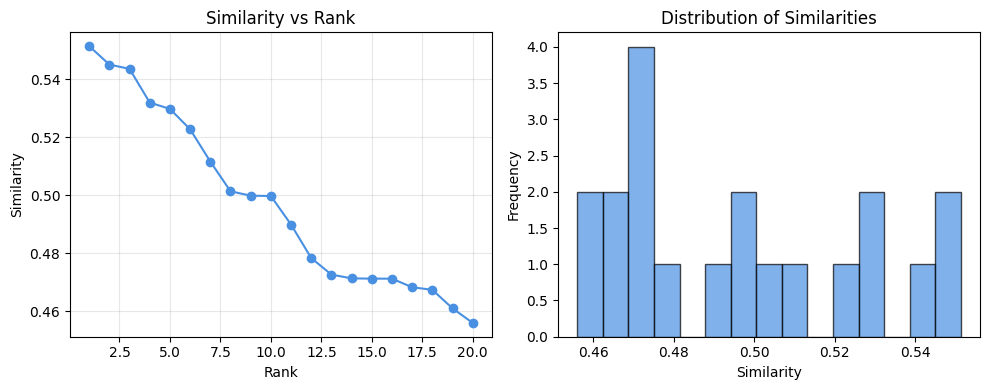

Query: What are neural networks?
Mean similarity: 0.497
Std similarity: 0.030


In [14]:
# Analizza distribuzione similarità
import matplotlib.pyplot as plt

query = "What are neural networks?"
results = retrieve(query, k=20)

similarities = [r['similarity'] for r in results]
ranks = [r['rank'] for r in results]

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(ranks, similarities, 'o-', color='#4A90E2')
plt.xlabel('Rank')
plt.ylabel('Similarity')
plt.title('Similarity vs Rank')
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.hist(similarities, bins=15, color='#4A90E2', alpha=0.7, edgecolor='black')
plt.xlabel('Similarity')
plt.ylabel('Frequency')
plt.title('Distribution of Similarities')

plt.tight_layout()
plt.show()

print(f"Query: {query}")
print(f"Mean similarity: {np.mean(similarities):.3f}")
print(f"Std similarity: {np.std(similarities):.3f}")

## Esercizi

1. **Aumenta dataset**: Rimuovi `df.head(500)` per usare l'intero dataset

2. **Hybrid search**: Implementa combinazione BM25 + embeddings
   ```python
   from rank_bm25 import BM25Okapi
   # Implementa funzione hybrid_retrieve()
   ```

3. **Re-ranking**: Usa cross-encoder per migliorare precision
   ```python
   from sentence_transformers import CrossEncoder
   reranker = CrossEncoder('cross-encoder/ms-marco-MiniLM-L-6-v2')
   ```

4. **Evaluation**: Crea test set e misura Precision@k

5. **Temperature tuning**: Sperimenta con temperature diverse (0.1-0.9)

6. **Modello migliore**: Sostituisci Qwen con Phi-2 per qualità superiore
   ```python
   model_id = "microsoft/phi-2"
   ```

In [15]:
!pip install rank_bm25

Ricerca Ibrida: Unione di Sintassi e Semantica
I modelli di embedding densi sono eccellenti per catturare il significato semantico (es. capiscono che "cane" e "cucciolo" sono correlati), ma spesso falliscono nella ricerca di keyword specifiche, acronimi o codici esatti.
Per superare questo limite implementiamo la **Hybrid Search**, combinando:
1. **Ricerca Lessicale (BM25):** Basata sulla frequenza esatta dei termini (TF-IDF avanzato).
2. **Ricerca Semantica (Dense Embeddings):** Basata sulla distanza vettoriale.

Poiché i due algoritmi restituiscono score su scale completamente diverse, applichiamo una **normalizzazione Min-Max** per portarli in un range $[0, 1]$ prima di calcolare la combinazione lineare:
$Score_{hybrid} = \alpha \cdot Score_{dense} + (1 - \alpha) \cdot Score_{BM25}$

In [16]:
#HYBRID SEARCH
from rank_bm25 import BM25Okapi
import numpy as np

tokenized_corpus = [doc.lower().split() for doc in documents]
bm25 = BM25Okapi(tokenized_corpus)

def hybrid_retrieve(query, k=5, alpha=0.5):

    #alpha: peso dato alla ricerca semantica (1-alpha al lessicale: 1 = 100% della ricerca semantica, 0.0 = 100% ricerca lessicale  )

    # Score Lessicale (BM25)
    tokenized_query = query.lower().split()
    bm25_scores = bm25.get_scores(tokenized_query)

    # Normalizzazione min-max
    if max(bm25_scores) > min(bm25_scores):
        bm25_scores = (bm25_scores - min(bm25_scores)) / (max(bm25_scores) - min(bm25_scores))

    # Score Semantico (Embeddings)
    # Codifichiamo la query e calcoliamo il prodotto scalare (che equivale alla cosine similarity se i vettori sono normalizzati)
    query_emb = embed_model.encode([query], convert_to_numpy=True, normalize_embeddings=True)
    dense_scores = np.dot(embeddings, query_emb.T).flatten()

    # Normalizzazione min-max per Similarità Coseno
    if max(dense_scores) > min(dense_scores):
        dense_scores = (dense_scores - min(dense_scores)) / (max(dense_scores) - min(dense_scores))

  # La normalizzazione ci serve perchè:
  #I punteggi dense_scores (Coseno) vanno rigorosamente da -1 a +1
  #I punteggi bm25_scores non hanno un limite superiore: possono essere 0, 10, 50 o 150 a seconda di quante volte la parola si ripete nel testo.
  #Se sommassi semplicemente 0.8 + 150, BM25 dominerebbe sempre. Quindi li uniamo normalizzandoli



    # Combinazione degli score (Formula Hybrid search)
    hybrid_scores = (alpha * dense_scores) + ((1 - alpha) * bm25_scores)

    # Estrazione dei top-k
    top_k_indices = np.argsort(hybrid_scores)[::-1][:k]

    results = []
    for i, idx in enumerate(top_k_indices):
        results.append({
            'rank': i + 1,
            'similarity': float(hybrid_scores[idx]),
            'document': documents[idx],
            'metadata': metadata[idx]
        })
    return results


In [17]:
query_test = "What are transformer models?"
print(f"RISULTATI RICERCA IBRIDA (Query: '{query_test}') ---")

# Eseguiamo la ricerca
risultati_ibridi = hybrid_retrieve(query_test, k=3, alpha=0.7)

# Cicliamo sui risultati per stamparli in modo pulito
for res in risultati_ibridi:
    titolo = res['metadata']['title']
    score = res['similarity']
    anno = res['metadata']['year']

    print(f"[{res['rank']}] Score Ibrido: {score:.3f}")
    print(f"    Titolo: {titolo} ({anno})")
    print(f"    Estratto: {res['document'][:100]}...\n")

RISULTATI RICERCA IBRIDA (Query: 'What are transformer models?') ---
[1] Score Ibrido: 0.852
    Titolo: Transformer models: an introduction and catalog (Unknown)
    Estratto: Title: Transformer models: an introduction and catalog

Abstract:   In the past few years we have se...

[2] Score Ibrido: 0.814
    Titolo: How Powerful are Decoder-Only Transformer Neural Models? (Unknown)
    Estratto: Title: How Powerful are Decoder-Only Transformer Neural Models?

Abstract:   In this article we prov...

[3] Score Ibrido: 0.717
    Titolo: Position Information in Transformers: An Overview (Unknown)
    Estratto: Title: Position Information in Transformers: An Overview

Abstract:   Transformers are arguably the ...



Two-Stage Retrieval e Re-ranking
Il recupero dei documenti avviene in due fasi per ottimizzare efficienza e precisione:
1. **Bi-Encoder (Fase 1):** Veloce ed efficiente. I documenti e le query vengono vettorializzati separatamente in anticipo. Recuperiamo un set ampio (es. $K=20$).
Problema: È molto veloce (può cercare su milioni di documenti in millisecondi), ma è superficiale. Poiché i vettori vengono calcolati separatamente, il modello non può vedere come le parole della query interagiscono semanticamente con le parole del documento.
2. **Cross-Encoder (Fase 2 - Re-ranking):** Estremamente preciso ma computazionalmente costoso. La query e ogni documento recuperato vengono passati *insieme* nella rete neurale. Il modello valuta le interazioni profonde (attention) tra le parole della query e quelle del documento, restituendo uno score di pertinenza molto più affidabile.

In [18]:
#RE-RANKING
from sentence_transformers import CrossEncoder
reranker = CrossEncoder('cross-encoder/ms-marco-MiniLM-L-6-v2')

def retrieve_with_rerank(query, initial_k=20, final_k=5):
    #Recupera initial_k documenti (20) e ne fa il re-ranking tenendo i migliori final_k

    # Retrieval primario usando l'indice FAISS già esistente
    initial_results = retrieve(query, k=initial_k)

    # Preparazione degli input per il Cross-Encoder: coppie (Query, Documento)
    cross_inp = [[query, res['document']] for res in initial_results]

    # Calcolo dei nuovi punteggi di pertinenza
    # I punteggi possono essere fortemente negativi (Documenti non utili) oppure fortemente positivi (Documenti utili)
    cross_scores = reranker.predict(cross_inp)

    # Assegnazione punteggi e ordinamento (Scorre i 20 documenti iniziali, assegnando il punteggio appena calcolato )
    for i in range(len(initial_results)):
        initial_results[i]['cross_score'] = float(cross_scores[i])

    reranked_results = sorted(initial_results, key=lambda x: x['cross_score'], reverse=True)

    # Aggiornamento rank finale
    for i, res in enumerate(reranked_results[:final_k]):
        res['rank'] = i + 1

    return reranked_results[:final_k]


config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

In [19]:
query_test = "Explain the attention mechanism"
print(f"RISULTATI RE-RANKING (Query: '{query_test}') ---")

# Recuperiamo 10 documenti e teniamo i migliori 3
risultati_rerank = retrieve_with_rerank(query_test, initial_k=10, final_k=3)

for res in risultati_rerank:
    titolo = res['metadata']['title']
    cross_score = res['cross_score']

    print(f"[{res['rank']}] Cross-Score: {cross_score:.3f}")
    print(f"    Titolo: {titolo}")
    print(f"    Estratto: {res['document'][:100]}...\n")

RISULTATI RE-RANKING (Query: 'Explain the attention mechanism') ---
[1] Cross-Score: 6.328
    Titolo: Does Attention Mechanism Possess the Feature of Human Reading? A
  Perspective of Sentiment Classification Task
    Estratto: Title: Does Attention Mechanism Possess the Feature of Human Reading? A
  Perspective of Sentiment C...

[2] Cross-Score: 5.055
    Titolo: Generalized Attention Mechanism and Relative Position for Transformer
    Estratto: Title: Generalized Attention Mechanism and Relative Position for Transformer

Abstract:   In this pa...

[3] Cross-Score: 4.569
    Titolo: How Far Does BERT Look At:Distance-based Clustering and Analysis of
  BERT$'$s Attention
    Estratto: Title: How Far Does BERT Look At:Distance-based Clustering and Analysis of
  BERT$'$s Attention

Abs...



Valutazione del Sistema: Precision@k
Per capire empiricamente se il nostro RAG funziona, usiamo metriche di Information Retrieval classiche come la **Precision@k**. Questa metrica indica la frazione di documenti rilevanti (noti a priori, ground truth) presenti nei primi $k$ risultati restituiti dal nostro sistema.
$\text{Precision}@k = \frac{\text{Documenti rilevanti trovati nei primi } k}{k}$
*(Un risultato di 0.0 può verificarsi se il dataset in memoria è incompleto, come nel caso di un sub-sample limitato).*

In [20]:
#CALCOLO PRECISION@K
def calculate_precision_at_k(retrieved_docs_titles, ground_truth_titles, k):
    #Calcola Precision@k misurando quanti titoli recuperati sono nei titoli corretti noti.
    # solo i primi k recuperati
    top_k_retrieved = retrieved_docs_titles[:k]
    # Conta le intersezioni tra risultati estratti e ground truth
    #Per ogni documento che è anche presente nella lista delle risposte corrette (ground_truth), aggiunge 1 al contatore
    relevant_retrieved = sum(1 for title in top_k_retrieved if title in ground_truth_titles)

    #Numero di HIT / numero di tentativi totali
    precision = relevant_retrieved / k
    return precision



In [35]:
# Esempio test:
query_eval = "BERT pre-training"
#abbiamo aumentato il numero di output del testo per trovare un effettivo caso utile
risultati = hybrid_retrieve(query_eval, k=10)
titoli_recuperati = [res['metadata']['title'] for res in risultati]

# Definiamo un titolo che sappiamo essere la risposta corretta
titoli_corretti = ["How to Fine-Tune BERT for Text Classification?"]

precision = calculate_precision_at_k(titoli_recuperati, titoli_corretti, k=3)

print("VALUTAZIONE PRECISION@3 \n")
print(f"Titoli trovati dal retriever: \n{titoli_recuperati}\n")
print(f"Valore Precision@3: {precision:.2f} (ovvero il {precision*100}% dei documenti estratti era corretto)")

VALUTAZIONE PRECISION@3 

Titoli trovati dal retriever: 
['How to Fine-Tune BERT for Text Classification?', 'Compressing BERT: Studying the Effects of Weight Pruning on Transfer\n  Learning', 'Pre-training technique to localize medical BERT and enhance biomedical\n  BERT', 'Learning to Win Lottery Tickets in BERT Transfer via Task-agnostic Mask\n  Training', 'MPNet: Masked and Permuted Pre-training for Language Understanding', 'On Losses for Modern Language Models', 'Improving Contextual Representation with Gloss Regularized Pre-training', 'EarlyBERT: Efficient BERT Training via Early-bird Lottery Tickets', 'Improving BERT with Hybrid Pooling Network and Drop Mask', 'Hierarchical Multitask Learning Approach for BERT']

Valore Precision@3: 0.33 (ovvero il 33.33333333333333% dei documenti estratti era corretto)


In [22]:
#Test TEMPERATURA da cambiare nel metodo rag_answer mettendo il parametro temperature come parametro di funzione e cambiando in fondo

# res_fattuale = rag_answer_tuned("What is BERT?", temperature=0.1)
# res_creativo = rag_answer_tuned("What is BERT?", temperature=0.8)

Ottimizzazione della Generazione (LLM e Temperatura)
* **Temperature Tuning:** In scenari RAG, vogliamo risposte fattuali ancorate al contesto. È buona pratica abbassare la temperatura (es. `temperature=0.1`) per ridurre la creatività del modello e minimizzare le allucinazioni.
Con una temperatura alta il modello "appiattisce" la distribuzione di probabilità. I candidati meno probabili guadagnano valore. Il modello inizia a fare scelte più azzardate.

Effetto nel RAG: È pericoloso. Se il contesto fornito è ambiguo o scarno, un'alta temperatura spingerà il modello a "colmare i buchi" con informazioni inventate che suonano plausibili ma sono errate.


* **Upgrade del Modello:** Sostituiamo il modello base con **Phi-2** di Microsoft.

In [23]:
#UTILIZZO DEL MODELLO MIGLIORE
from transformers import AutoTokenizer, AutoModelForCausalLM, pipeline, AutoConfig

model_id = "microsoft/phi-2"

# Per Phi-2 è essenziale trust_remote_code=True
tokenizer_phi = AutoTokenizer.from_pretrained(model_id, trust_remote_code=True)

# Gestione esplicita del padding.
if tokenizer_phi.pad_token is None:
    tokenizer_phi.pad_token = tokenizer_phi.eos_token
    # Also set pad_token_id in the tokenizer if it's still None
    if tokenizer_phi.pad_token_id is None:
        tokenizer_phi.pad_token_id = tokenizer_phi.eos_token_id

## Caricamento della configurazione del modello
config_phi = AutoConfig.from_pretrained(model_id, trust_remote_code=True)

# Patching della configurazione per assicurare che il modello conosca il pad_token_id
if not hasattr(config_phi, 'pad_token_id') or config_phi.pad_token_id is None:
    config_phi.pad_token_id = tokenizer_phi.eos_token_id


# Caricamento dei pesi del modello.
model_phi = AutoModelForCausalLM.from_pretrained(
    model_id,
    config=config_phi, # Pass the modified config
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto" if torch.cuda.is_available() else None,
    trust_remote_code=True,
    low_cpu_mem_usage=True
)

llm_phi = pipeline(
    'text-generation',
    model=model_phi,
    tokenizer=tokenizer_phi,
    device=0 if torch.cuda.is_available() else -1,
    max_new_tokens=300,
)

config.json:   0%|          | 0.00/735 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.34k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/1.08k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.7k [00:00<?, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/453 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

In [24]:
# A differenza di Qwen che usava i chat template standard, Phi-2 risponde bene al formato Instruct.
# Nella funzione rag_answer(), cambiare i prompts con :
"""
prompt = f"Instruct: You are an NLP research assistant. Answer the question based ONLY on the provided context.\n\nContext:\n{context}\n\nQuestion: {query}\nOutput:"
"""

'\nprompt = f"Instruct: You are an NLP research assistant. Answer the question based ONLY on the provided context.\n\nContext:\n{context}\n\nQuestion: {query}\nOutput:"\n'

Test Fattuali e Definizioni
Ideali per verificare la precisione della ricerca lessicale (BM25) e l'impostazione della temperatura bassa (es. 0.1). L'assistente deve rispondere in modo preciso e conciso.

"What is the BERT model and what does its acronym stand for?"

"Explain the exact mechanism of Multi-Head Attention in transformers."

"What is the mathematical definition of the BLEU score in machine translation?"

"Define Byte-Pair Encoding (BPE) and why it is used in tokenization."

2. Test di Sintesi e Ragionamento
Ideali per mettere alla prova il Re-ranking (Cross-Encoder) e le capacità di sintesi avanzate del nuovo modello Microsoft Phi-2. Richiedono di unire concetti da più paragrafi.

"Summarize the main advantages of using Transformers over traditional Recurrent Neural Networks (RNNs)."

"How does transfer learning improve the performance of NLP models when training data is limited?"

"Discuss the primary limitations of the original Transformer architecture when handling very long documents."

"Compare Cross-Encoders and Bi-Encoders: what are the trade-offs between speed and accuracy?"

3. Test di Esplorazione Creativa o Prospettica
Ideali per testare l'impostazione della temperatura alta (es. 0.7 - 0.9). L'assistente dovrebbe generare risposte più discorsive, elaborando i concetti estratti.

"Based on the documents, what are the most promising future trends in Natural Language Generation?"

"Explain the concept of Zero-Shot learning to someone who is not an expert in artificial intelligence."

"What are the ethical concerns or biases associated with training large language models on internet data?"

4. Test "Stress" e Controllo Allucinazioni
Fondamentali per verificare se il sistema è "ancorato" al contesto. Se il documento non contiene la risposta, l'assistente deve ammettere di non saperlo o rifiutarsi di inventare.

"What does the provided context say about the cure for the common cold?" (Test fuori dominio).

"According to the documents, who won the World Cup in 2022?" (Test su dati fattuali non presenti nei paper NLP).

"Can you summarize the plot of the movie Inception based on the context?" (Test per forzare un'allucinazione).

Suggerimento per l'inserimento interattivo: cambiare la temperatura e le varie query per vedere i risultati differenti in base alle varie caratteristiche

## Risorse

**Paper**:
- Lewis et al. (2020). Retrieval-Augmented Generation. arXiv:2005.11401
- Karpukhin et al. (2020). Dense Passage Retrieval. arXiv:2004.04906

**Documentazione**:
- HuggingFace Transformers: https://huggingface.co/docs/transformers
- Sentence Transformers: https://www.sbert.net
- FAISS: https://github.com/facebookresearch/faiss

**Modelli alternativi**:
- SmolLM-360M: più veloce (~300MB)
- Phi-2: migliore qualità (~5GB)
- GPT-3.5 (API): qualità superiore ma richiede API key